# 🏪 6-7 Store — Test & Control Optimization Algorithm
### Optimal Selection of Brick-and-Mortar Experimental Groups via Mixed-Integer Linear Programming (MILP)

*Notebook 1 of 2 · Next: [`results.ipynb`](results.ipynb) (validation and diagnostics)*

---

> **Business context:**
> **6-7 Store** (a U.S. convenience chain with more than 2,000 stores across 50 states) needs to evaluate a new **dynamic pricing** initiative. To make sure the A/B test results are statistically valid and free of selection bias, this notebook develops and runs the **`optimal-store-test-control`** algorithm.
>
> *Note: synthetic dataset created for portfolio and technical demonstration purposes. "6-7 Store" is a parody brand with no affiliation to any real company.*

**What this notebook does:**
1. Loads daily store-level sales history.
2. Assigns a stratified 25% sample of the stores in each state to the **test group**.
3. Solves a MILP per state to pick a **control group** whose aggregate daily sales best match the test group.
4. Exports the labeled dataset for analysis in `results.ipynb`.

## 1. Mathematical Formulation of the Problem

Instead of relying on approximate heuristics (such as nearest-neighbor or pointwise propensity score matching), we formulate control group selection as a **Mixed-Integer Linear Programming (MILP)** problem.

The algorithm is solved independently for each state, which controls for geographic heterogeneity.

### Notation:
- $\mathcal{S}$: Set of candidate control stores in the state.
- $\mathcal{T}$: Set of days with observed history ($t \in \{1, \dots, T\}$).
- $N_{\text{test}}$: Number of stores sampled into the test group in the state.
- $S_{i,t}$: Sales volume of candidate store $i \in \mathcal{S}$ on day $t$.
- $Y_t$: Total sales volume of the test group on day $t$: $Y_t = \sum_{j \in \text{Test}} S_{j,t}$.

### Decision Variables:
- $x_i \in \{0, 1\}$: Binary variable indicating whether store $i$ is selected for the control group ($1$) or not ($0$).
- $d_t \ge 0$: Auxiliary continuous variable representing the absolute deviation on day $t$.

### Objective Function:
$$\min \sum_{t \in \mathcal{T}} d_t$$

### Constraints:
1. **Linearization of the Daily Absolute Distance ($L_1$ Norm):**
   $$d_t \ge \sum_{i \in \mathcal{S}} x_i \cdot S_{i,t} - Y_t, \quad \forall t \in \mathcal{T}$$
   $$d_t \ge Y_t - \sum_{i \in \mathcal{S}} x_i \cdot S_{i,t}, \quad \forall t \in \mathcal{T}$$
2. **Store Count Parity:**
   $$\sum_{i \in \mathcal{S}} x_i = N_{\text{test}}$$
3. **Domains:**
   $$x_i \in \{0, 1\}, \quad d_t \ge 0$$

In [1]:
# Setup and library imports
import pandas as pd
import numpy as np
import pytz
import pulp
import random
from datetime import datetime
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

import warnings
warnings.filterwarnings('ignore')

print(f'PuLP version: {pulp.__version__}')
print(f'Pandas version: {pd.__version__}')

PuLP version: 4.3.1
Pandas version: 2.3.3


## 2. Loading and Inspecting the Historical Data

We load the historical daily sales data from a Parquet file (`input_data/df_sales.parquet`). The dataset covers **2,046 stores across 50 U.S. states** from January 1 to November 17, 2026 (321 days), with 632,215 store-day records.

In [2]:
# Read the historical dataset
df_complete = pd.read_parquet('input_data/df_sales.parquet', engine='pyarrow')

print(f'Dataset shape: {df_complete.shape[0]:,} rows x {df_complete.shape[1]} columns')
print(f'Unique stores: {df_complete["store_id"].nunique():,}')
print(f'States covered: {df_complete["state"].nunique()}')
print(f'Date range: {df_complete["dt_ref"].min()} to {df_complete["dt_ref"].max()}')

# Show a data sample
display(df_complete.head(5))
display(df_complete[['net_sales', 'gross_sales', 'qty_sold']].describe())

Dataset shape: 632,215 rows x 7 columns
Unique stores: 2,046
States covered: 50
Date range: 2026-01-01 to 2026-11-17


,dt_ref,store_id,state,sales_region,net_sales,gross_sales,qty_sold
0,2026-01-01,STORE-0067,New York,Northeast,36361.16,42056.28,4019
1,2026-01-01,STORE-0074,New York,Northeast,54537.80,66148.37,4312
2,2026-01-01,STORE-0264,Michigan,Midwest,6662.84,7734.35,567
3,2026-01-01,STORE-0307,Connecticut,Northeast,15012.83,19541.29,2383
4,2026-01-01,STORE-0384,New York,Northeast,36296.36,44760.88,3033


,net_sales,gross_sales,qty_sold
count,6.322150e+05,6.322150e+05,632215.000000
mean,2.187742e+04,2.633124e+04,2765.647422
std,2.287679e+04,2.690881e+04,3899.863232
min,6.300000e-01,6.900000e-01,1.000000
25%,1.067535e+04,1.286072e+04,1334.000000
50%,1.619657e+04,1.950156e+04,2036.000000
75%,2.580967e+04,3.109468e+04,3218.000000
max,2.827760e+06,2.884773e+06,679834.000000


## 3. Stratified Sampling to Define the Test Group

Simple stratified sampling by state ensures that each state contributes exactly the target share of its stores to the test group (the recommended range is 20%–40%; here it is set to **25%**).

This avoids imbalances in which a state would be over-represented in, or missing from, the experiment.

In [3]:
def create_test_group(df: pd.DataFrame, percent_test: float = 0.25, seed: int = 42) -> pd.DataFrame:
    """
    Builds the test group using simple stratified random sampling.

    Parameters:
        df (pd.DataFrame): Sales history DataFrame containing 'store_id'.
        percent_test (float): Share of stores to select (default: 0.25).
        seed (int): Random seed for reproducibility.

    Returns:
        pd.DataFrame: DataFrame with an additional 'flag_test_control' column ('test' or NaN).
    """
    rng = random.Random(seed)
    all_stores = sorted(df['store_id'].unique())
    store_count = int(len(all_stores) * percent_test)

    if store_count == 0:
        return df.assign(flag_test_control=np.nan)

    selected_test = rng.sample(all_stores, store_count)
    df_test_flags = pd.DataFrame({'store_id': selected_test, 'flag_test_control': 'test'})

    return pd.merge(df, df_test_flags, on='store_id', how='left')

## 4. Combinatorial Optimization Engine (PuLP Solver)

The `stores_optimizer` function implements the MILP formulation presented in section 1:
1. Separates the stores sampled into the test group and identifies the candidate control stores in the state.
2. Computes the test group's daily sales total ($Y_t$).
3. Creates the binary decision variables $x_i \in \{0, 1\}$ and the continuous variables $d_t \ge 0$.
4. Adds the linear constraints that bound the $L_1$ norm of the daily error.
5. Adds the cardinality constraint $\sum x_i = N_{\text{test}}$.
6. Runs the **COIN-OR CBC** solver through PuLP with a time limit and a relative-gap tolerance.
7. Returns the store mapping with the `test` and `control` flags.

In [4]:
def stores_optimizer(df_state: pd.DataFrame, criteria: str, time_limit: float):
    """
    Selects the optimal control group for one state by solving the MILP described in section 1.

    Parameters:
        df_state (pd.DataFrame): Sales history of one state, with the 'flag_test_control' column.
        criteria (str): Metric to match ('qty_sold', 'net_sales' or 'gross_sales').
        time_limit (float): Maximum solver run time, in seconds.

    Returns:
        pd.DataFrame: 'store_id' and 'flag' ('test' or 'control') for the stores in the experiment.
    """
    df = df_state.copy()
    state = df['state'].values[0]
    # 1. GROUP IDENTIFICATION
    # Stores that belong to the test group
    list_store_test = (df.loc[df['flag_test_control'] == 'test', 'store_id'].dropna().unique().tolist())
    df_store_test = pd.DataFrame({'store_id': list_store_test, 'flag': 'test'})

    # Group labeling
    df_temp_opt = df.merge(df_store_test, on='store_id', how='left')
    df_temp_opt['flag'] = df_temp_opt['flag'].fillna('control')

    # 2. DATA PREPARATION
    # Candidate control stores
    store_set = (df_temp_opt.loc[df_temp_opt['flag'] == 'control', 'store_id'].dropna().unique().tolist())

    # Number of test stores
    n_test_stores = len(list_store_test)

    # Daily sales of the test group
    daily_sales = (df_temp_opt.loc[df_temp_opt['flag'] == 'test'].groupby('dt_ref')[criteria].sum().to_dict())

    # Daily sales per candidate control store
    sales_store_id = (df_temp_opt.loc[df_temp_opt['flag'] == 'control'].groupby(['store_id', 'dt_ref'])[criteria].sum().to_dict())


    # 3. PROBLEM DECLARATION
    prob = pulp.LpProblem('experiment_design', pulp.LpMinimize)

    # Binary store-selection variables
    x = prob.add_variable_dicts('store_id', store_set, lowBound=0, upBound=1, cat=pulp.LpInteger)

    # Absolute percentage difference per day
    sales_dif = prob.add_variable_dicts('sales_dif', list(daily_sales.keys()), lowBound=0, cat=pulp.LpContinuous)


    # 4. CONSTRAINTS
    for day in daily_sales:
        sales_control = pulp.lpSum(x[store] * sales_store_id.get((store, day), 0) for store in store_set)

        # Normalization by the test group's sales
        denominator = max(abs(daily_sales[day]), 1)
        difference = (sales_control - daily_sales[day]) / denominator
        # Absolute value of the percentage difference
        prob += sales_dif[day] >= difference
        prob += sales_dif[day] >= -difference


    # 5. OBJECTIVE FUNCTION
    prob += pulp.lpSum(sales_dif[day] for day in daily_sales)

    # 6. STORE COUNT CONSTRAINT
    prob += (pulp.lpSum(x[store] for store in store_set) == n_test_stores)

    # 6. CONSTRAINTS
    # C1: Minimize the absolute difference in daily sales
    for day in daily_sales:
        sales_control = pulp.lpSum(x[store] * sales_store_id.get((store, day), 0) for store in store_set)
        prob += (sales_dif[day] >= sales_control - daily_sales[day])
        prob += (sales_dif[day] >= daily_sales[day] - sales_control)

    # C2: Match the number of stores in both groups
    prob += (pulp.lpSum(x[store] for store in store_set) == n_test_stores)


    # 7. SOLVING
    solver = pulp.COIN_CMD(msg=0, timeLimit=time_limit, gapRel=0.001)
    stats = prob.solve(solver)

    # 8. EXTRACTING THE RESULTS
    if not stats.has_solution:
        print(f'The model could not find a solution for state {state}')
        return pd.DataFrame()

    control_group_store = [store for store in store_set if x[store].value() is not None and x[store].value() > 0.5]
    control_group = pd.DataFrame({
        'store_id': control_group_store,
        'flag': 'control'
    })

    return pd.concat([control_group, df_store_test], ignore_index=True)

## 5. Running the Algorithm for Each State

Parameter definitions:
- `TIME_LIMIT`: Maximum time, in seconds, the solver may run per state. Once the limit is reached, the solver returns the best solution found so far.
- `PERCENT_TEST_STORES`: Share of the stores in each state assigned to the test group.
- `CRITERIA`: Metric the objective function minimizes. It can be `qty_sold`, `net_sales`, or `gross_sales`.

> **Note on the saved outputs:** the results stored in this notebook (and analyzed in `results.ipynb`) come from a run on a **single state, Florida**, with 28 test stores and 28 optimized control stores. As written, the loop below iterates over every state in the dataset; to reproduce the saved outputs exactly, restrict `states` to `['Florida']`.

In [5]:
TIME_LIMIT = 360
PERCENT_TEST_STORES = 0.25
CRITERIA = 'qty_sold'
df_temp = []
lst_df_result = []

states = sorted(df_complete['state'].unique().tolist())

for state in tqdm(states):
    processing_datetime = datetime.now(tz = pytz.timezone('America/Chicago'))

    df_state = df_complete.loc[df_complete['state'] == state]
    test_id = str(state) + '-' + str(processing_datetime).split(' ')[0]

    # Creating test group
    df_state = create_test_group(df=df_state, percent_test=PERCENT_TEST_STORES, seed=42)

    if df_state is not None:
        df_temp = stores_optimizer(df_state, criteria=CRITERIA, time_limit=TIME_LIMIT)
        df_temp['processing_datetime'] = processing_datetime

        # Running the optimization algorithm
        lst_df_result.append(df_temp)


df_result = pd.concat(lst_df_result)
df_result = pd.merge(df_complete, df_result, how='left', on=['store_id'])

100%|██████████| 50/50 [26:15<00:00, 31.52s/it]  


## 6. Quick Visual Validation of the Time Series (Plotly)

We check the daily aggregate alignment between the test group and the optimized control group over the 2026 sample period (January 1 – November 17).

#### Seaborn

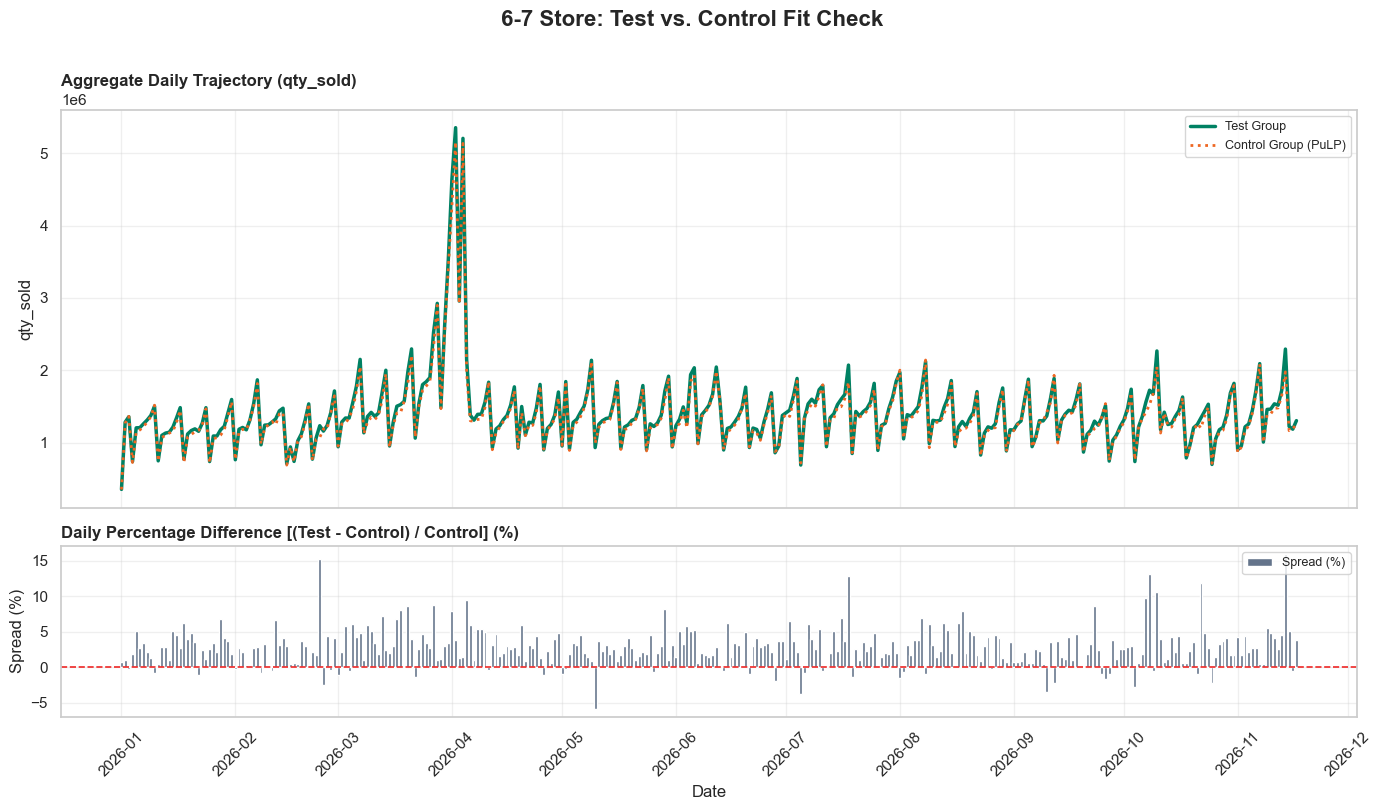

Mean percentage difference: 2.73%
Pearson correlation: 0.9968


In [6]:
# 1. DAILY AGGREGATION
df_plot = (df_result[df_result['flag'].isin(['test', 'control'])] .groupby(['dt_ref', 'flag'], as_index=False)[CRITERIA] .sum())
df_plot['dt_ref'] = pd.to_datetime(df_plot['dt_ref'])

df_pivot = (df_plot.pivot(index='dt_ref', columns='flag', values=CRITERIA).sort_index())
df_pivot['diff_pct'] = ((df_pivot['test'] - df_pivot['control']) / df_pivot['control']) * 100

# 2. CHART CONFIGURATION
sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [0.7, 0.3]})

# 3. AGGREGATE DAILY TRAJECTORY
df_pivot_plot = df_pivot.reset_index()

# Test & Control Group
sns.lineplot(data=df_pivot_plot, x='dt_ref', y='test', ax=axes[0], color='#008163', linewidth=2.5, label='Test Group')
sns.lineplot(data=df_pivot_plot, x='dt_ref', y='control', ax=axes[0], color='#EE6723', linewidth=2, linestyle=':', label='Control Group (PuLP)')

axes[0].set_title(f'Aggregate Daily Trajectory ({CRITERIA})', fontsize=12, fontweight='bold', loc='left')
axes[0].set_ylabel(CRITERIA)
axes[0].set_xlabel('')
axes[0].legend(loc='upper right', fontsize=9)

# 4. DAILY PERCENTAGE DIFFERENCE
axes[1].bar(df_pivot.index, df_pivot['diff_pct'], color='#64748B', width=0.8, label='Spread (%)')

# Zero reference line
axes[1].axhline(y=0, color='#EE2726', linestyle='--', linewidth=1.2)
axes[1].set_title('Daily Percentage Difference [(Test - Control) / Control] (%)', fontsize=12, fontweight='bold', loc='left')
axes[1].set_ylabel('Spread (%)')
axes[1].set_xlabel('Date')
axes[1].legend(loc='upper right', fontsize=9)

# 5. GENERAL FORMATTING
fig.suptitle('6-7 Store: Test vs. Control Fit Check', fontsize=16, fontweight='bold', y=1.01)

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. STATISTICAL METRICS
print(f'Mean percentage difference: {df_pivot["diff_pct"].mean():.2f}%')
print(f'Pearson correlation: {df_pivot["test"].corr(df_pivot["control"]):.4f}')

#### Plotly

In [7]:
# Daily aggregation for a quick visualization
df_plot = (
    df_result[df_result['flag'].isin(['test', 'control'])]
    .groupby(['dt_ref', 'flag'], as_index=False)[CRITERIA]
    .sum()
)
df_plot['dt_ref'] = pd.to_datetime(df_plot['dt_ref'])
df_pivot = df_plot.pivot(index='dt_ref', columns='flag', values=CRITERIA).sort_index()
df_pivot['diff_pct'] = ((df_pivot['test'] - df_pivot['control']) / df_pivot['control']) * 100

# Interactive chart with the 7-Eleven-inspired palette (#008163 green, #EE6723 orange)
fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
    row_heights=[0.7, 0.3],
    subplot_titles=(f'Aggregate Daily Trajectory ({CRITERIA})', 'Daily Percentage Difference [(Test - Control) / Control] (%)')
)

# Time series curves
fig.add_trace(go.Scatter(x=df_pivot.index, y=df_pivot['test'], mode='lines', name='Test Group', line=dict(color='#008163', width=2.5)), row=1, col=1)
fig.add_trace(go.Scatter(x=df_pivot.index, y=df_pivot['control'], mode='lines', name='Control Group (PuLP)', line=dict(color='#EE6723', width=2, dash='dot')), row=1, col=1)

# Residual bars
fig.add_trace(go.Bar(x=df_pivot.index, y=df_pivot['diff_pct'], name='Spread (%)', marker_color='#64748B'), row=2, col=1)
fig.add_hline(y=0, line_dash='dash', line_color='#EE2726', row=2, col=1)

fig.update_layout(
    title=dict(text='<b>6-7 Store: Test vs. Control Fit Check</b>', x=0.5),
    template='plotly_white',
    height=650,
    hovermode='x unified'
)
fig.show()

print(f'Mean percentage difference: {df_pivot["diff_pct"].mean():.2f}%')
print(f'Pearson correlation: {df_pivot["test"].corr(df_pivot["control"]):.4f}')

Mean percentage difference: 2.73%
Pearson correlation: 0.9968


## 7. Exporting the Structured Results

We persist the dataset with the assigned groups as a Gzip-compressed Parquet file at `output_data/df_results.parquet`.

In [8]:
import os
os.makedirs('output_data', exist_ok=True)

# Export the results
df_result.to_parquet('output_data/df_results.parquet', compression='gzip', engine='pyarrow')

print('Dataset saved successfully to:')
print('- output_data/df_results.parquet')

Dataset saved successfully to:
- output_data/df_results.parquet


You can follow the results analysis in [`results.ipynb`](results.ipynb).